In [49]:
import torch
torch.manual_seed(0)
from train_mnist import get_model 
model = get_model()
model.load_state_dict(torch.load("mnist_cnn.pt", map_location="cpu"))
model

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Flatten(start_dim=1, end_dim=-1)
  (15): Linear(in_features=3136, out_features=256, bias=True)
  (16): ReLU()
  (17):

In [57]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

data = datasets.MNIST("data", download=True, transform=tf)
class WithIdx(torch.utils.data.Dataset):
    def __init__(self, ds): self.ds = ds
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        x, y = self.ds[i]
        return x, y, i
loader = DataLoader(WithIdx(data), batch_size=128, shuffle=True)


model[16]._forward_hooks.clear()

emb = []
def hook(m, inp, out):
	global emb
	emb.append(out.detach())
model[16].register_forward_hook(hook)

ixs = []

model.eval()
for x, y, i in loader:
	with torch.no_grad():
		model(x)
		ixs.extend(i)
	break

EMB = torch.cat(emb)
ixs = torch.tensor(ixs)
EMB.shape, ixs.shape

(torch.Size([128, 256]), torch.Size([128]))

kNN graph
- each node has k nearest points

A neighbor's neighbor might be closer. a -> i -> b
$$d(a, b) \le d(a, i) + d(i, b)$$

In [100]:
k = 10

# brute force method here
D = torch.cdist(EMB, EMB)
kNN_exact_dist, kNN_exact_pos = D.topk(k, dim=1, largest=False)
kNN_exact_dist.shape, kNN_exact_pos.shape

(torch.Size([128, 10]), torch.Size([128, 10]))

Below is the attempted NN-descent. But its really painful
the claude solution is not batched. So i'm just moving on

In [99]:
B, C = EMB.shape
k = 10
delta = 0.001

probs = torch.ones(B, B)
probs.fill_diagonal_(0) # don't self select
neighbors = torch.multinomial(probs, k, replacement=False) # random indices
dists = ((EMB[:, None, :] - EMB[neighbors])**2).sum(-1)
is_new = torch.full((B,k), True)

def try_update(i, j, d):
	# update i, with j
	res = torch.ones_like(i)
	m1 = (neighbors[i] == j[:,None]).any(dim=1)
	m2 = (d < dists[i, -1])
	ok = m1 & ~m2
	res = ok.long()

	idx = i[ok]

	# update those that pass mask
	neighbors[idx, -1], dists[idx, -1] = j[ok], d[ok]
	is_new[idx, -1] = True

	# reorder row
	order = dists[idx].argsort()
	neighbors[idx], dists[idx] = neighbors[idx].gather(1, order), dists[idx].gather(1, order)
	is_new[idx] = is_new[idx].gather(1, order)

	return res.sum()


# NN-descent
while True:
	updates = 0
	for i in range(B):
		# other idx that contains i
		# new_i = neighbors[i][is_new[i]]
		# old_i = neighbors[i][~is_new[i]]
		# is_new[i][sampled] = False 

		reverse_neighbors = (neighbors == i).any(1)
		cands = torch.cat([neighbors[i], reverse_neighbors], dim=0)
		cands = cands.unique()
		p, q = torch.cartesian_prod(cands, cands).unbind(1)
		m = p < q
		p, q = p[m], q[m] # self pairs, 
		d = ((EMB[p]-EMB[q])**2).sum(-1)

		# update i's neighbors
		updates += try_update(p, q, d)
		# update j's neighbors
		updates += try_update(p, q, d)

	if updates < delta * B * k:
		break

dist[:3]


KeyboardInterrupt: 

finding variance again
$$\sum_{j \in \text{kNN}(i)} \exp\!\left(-\frac{d_{ij} - \rho_i}{\sigma_i}\right) = \log_2 k$$

In [113]:
# find sigma, copying tsne binary search

perp_target = torch.log2(torch.tensor(k))
lo, hi = torch.zeros(B), torch.full((B,), float('inf'))
std = torch.ones(B)*20

p_i = kNN_exact_dist.min(1).values

while True:
	# emb: (B, C)
	# pair wise sub (B, B, C) ==> x_i - x_j
	perp_i = torch.exp(- (kNN_exact_dist - p_i[:,None]) / std[:,None]).sum(1)

	if torch.all(torch.abs(perp_i - perp_target) < 1e-5) or (hi-lo).max() < 1e-4:
		break

	mask = perp_i > perp_target

	hi[mask] = std[mask]
	std[mask] = (lo[mask] + hi[mask])/2
	lo[~mask] = std[~mask]

	unb = ~mask & torch.isinf(hi)
	bnd = ~mask & ~torch.isinf(hi)
	std[unb] = std[unb] * 2
	std[bnd] = (lo[bnd] + hi[bnd]) / 2

std

tensor([17.4444, 25.5233, 21.1457, 18.9902, 20.7600, 23.9585, 21.1012,  8.0320,
        26.6122, 22.9805, 23.4718, 24.3454, 18.0792, 16.4057,  6.0547, 23.8519,
        18.6857, 17.8909, 16.8360, 17.2570, 21.8638, 17.4951, 29.3245, 27.5914,
         7.1766, 21.6802, 19.3708, 18.8746, 24.5379, 24.3447, 17.8687, 24.6199,
        20.0068, 17.3455, 23.8818, 14.5061,  8.1466,  6.3630, 12.9253, 14.7423,
        21.2283, 10.7869, 16.1723, 21.4606, 18.3560,  7.0866, 26.9859, 16.1515,
        21.0839, 17.2478, 10.8085,  8.9868, 17.9283, 19.7332,  8.2280, 19.8570,
        17.2577, 18.0256, 18.6595, 27.6028, 19.5568, 21.4068, 27.8037, 20.3232,
        24.3943, 22.6439, 26.2240, 17.6307, 17.8491, 21.0158, 19.4815, 19.4938,
         6.1434, 19.2838, 16.8413, 28.7916, 25.5938, 18.4487, 26.5651, 14.6989,
         5.6341, 21.6178, 19.2804, 17.7294, 21.6008, 18.2165, 20.9924, 17.9769,
        18.9223, 19.8322, 27.1962, 25.1120, 24.0676, 23.3992, 28.0088, 23.2267,
        21.8627, 20.5002, 20.9088, 25.46

Instead of gaussian, we use laplacian exp decay

$$v_{j|i} = \exp\!\left(-\frac{d(x_i, x_j) - \rho_i}{\sigma_i}\right)$$

$\rho_i$ is the smallest neighbor distance

$$0 < v_{j|i} \leq 1$$

In [119]:
v_ji = torch.exp(- (kNN_exact_dist - p_i[:,None]) / std[:,None] )
v_ji.shape

torch.Size([128, 10])

Symmetrize, so called fuzzy union
$$v_{ij} = v_{j|i} + v_{i|j} - v_{j|i}\, v_{i|j}$$

ngl, couldn't understand the tensor dims so mostly claude guiding here

In [127]:
j = kNN_exact_pos # the (N,k) orderings
v_ij = torch.exp(-(kNN_exact_dist - p_i[j]).clamp(min=0) / std[j])
in_j = (kNN_exact_pos[j] == torch.arange(B)[:, None, None]).any(-1)
v_ij = v_ij * in_j
v = v_ji + v_ij - v_ji * v_ij
v.shape

torch.Size([128, 10])

Low dims. because of a similar crowding problem we use heavy tailed
$$w_{ij} = \left(1 + a\,\|y_i - y_j\|^{2b}\right)^{-1}$$

In [128]:
import numpy as np
from scipy.optimize import curve_fit

# fake embedding
y = torch.randn(B, 2).requires_grad_()

def find_ab(spread=1.0, min_dist=0.1):
    x = np.linspace(0, spread * 3, 300)
    y = np.where(x < min_dist, 1.0, np.exp(-(x - min_dist) / spread))
    f = lambda x, a, b: 1.0 / (1.0 + a * x ** (2 * b))
    (a, b), _ = curve_fit(f, x, y)
    return a, b

a, b = find_ab()

d2 = ((y[None] - y[:, None])**(2)).sum(-1)
w = -torch.log1p(a*d2**b)
w.shape

torch.Size([128, 128])

Binary x entropy loss:

$$ KL(V \| W) = H(V,W) - H(V) $$

$$KL(\text{Bern}(v)\,\|\,\text{Bern}(w)) = \underbrace{-v\log w - (1-v)\log(1-w)}_{\text{binary cross-entropy}} - \underbrace{\left[-v\log v - (1-v)\log(1-v)\right]}_{\text{entropy of } v,\ \text{constant}}$$

$$C = \sum_{i \neq j} \underbrace{v_{ij} \log\frac{v_{ij}}{w_{ij}}}_{\text{attract}} + \underbrace{(1 - v_{ij}) \log\frac{1 - v_{ij}}{1 - w_{ij}}}_{\text{repel}}$$

In [130]:
# make v also (N,N)
V = torch.zeros(B, B)
V[torch.arange(B)[:, None], kNN_exact_pos] = v
V = V + V.T - V * V.T

eps = 1e-4
att = -V * torch.log(w.clamp(min=eps))
rep = - (1 - V) * torch.log((1 - w).clamp(min=eps))

loss = att + rep
loss = loss[~torch.eye(B, dtype=torch.bool)].sum()
loss

tensor(-6602.6104, grad_fn=<SumBackward0>)

Let's use autograd and torchify this

In [140]:
lossi = []
eps = 1e-4
# anything v is held constant

# learn this!
y = torch.randn(B, 2).requires_grad_()
optimizer = torch.optim.Adam([y], lr=0.1)

for _ in range(10000):

	d2 = ((y[None] - y[:, None])**(2)).sum(-1) + 1e-8 # diagonals is d2=0 which makes gradient nan
	w = -1/(1+a*d2**b)
	
	att = -V * torch.log(w.clamp(min=eps))
	rep = - (1 - V) * torch.log((1 - w).clamp(min=eps))

	loss = att + rep
	loss = loss[~torch.eye(B, dtype=torch.bool)].sum()

	lossi.append(loss.item())

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

print(loss)

tensor(-3922.2043, grad_fn=<SumBackward0>)


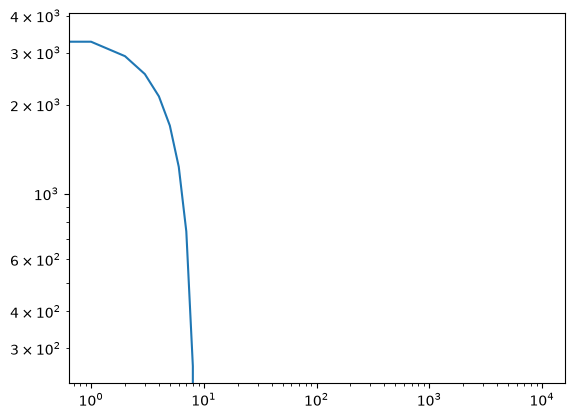

In [141]:
import matplotlib.pyplot as plt
plt.loglog(lossi)

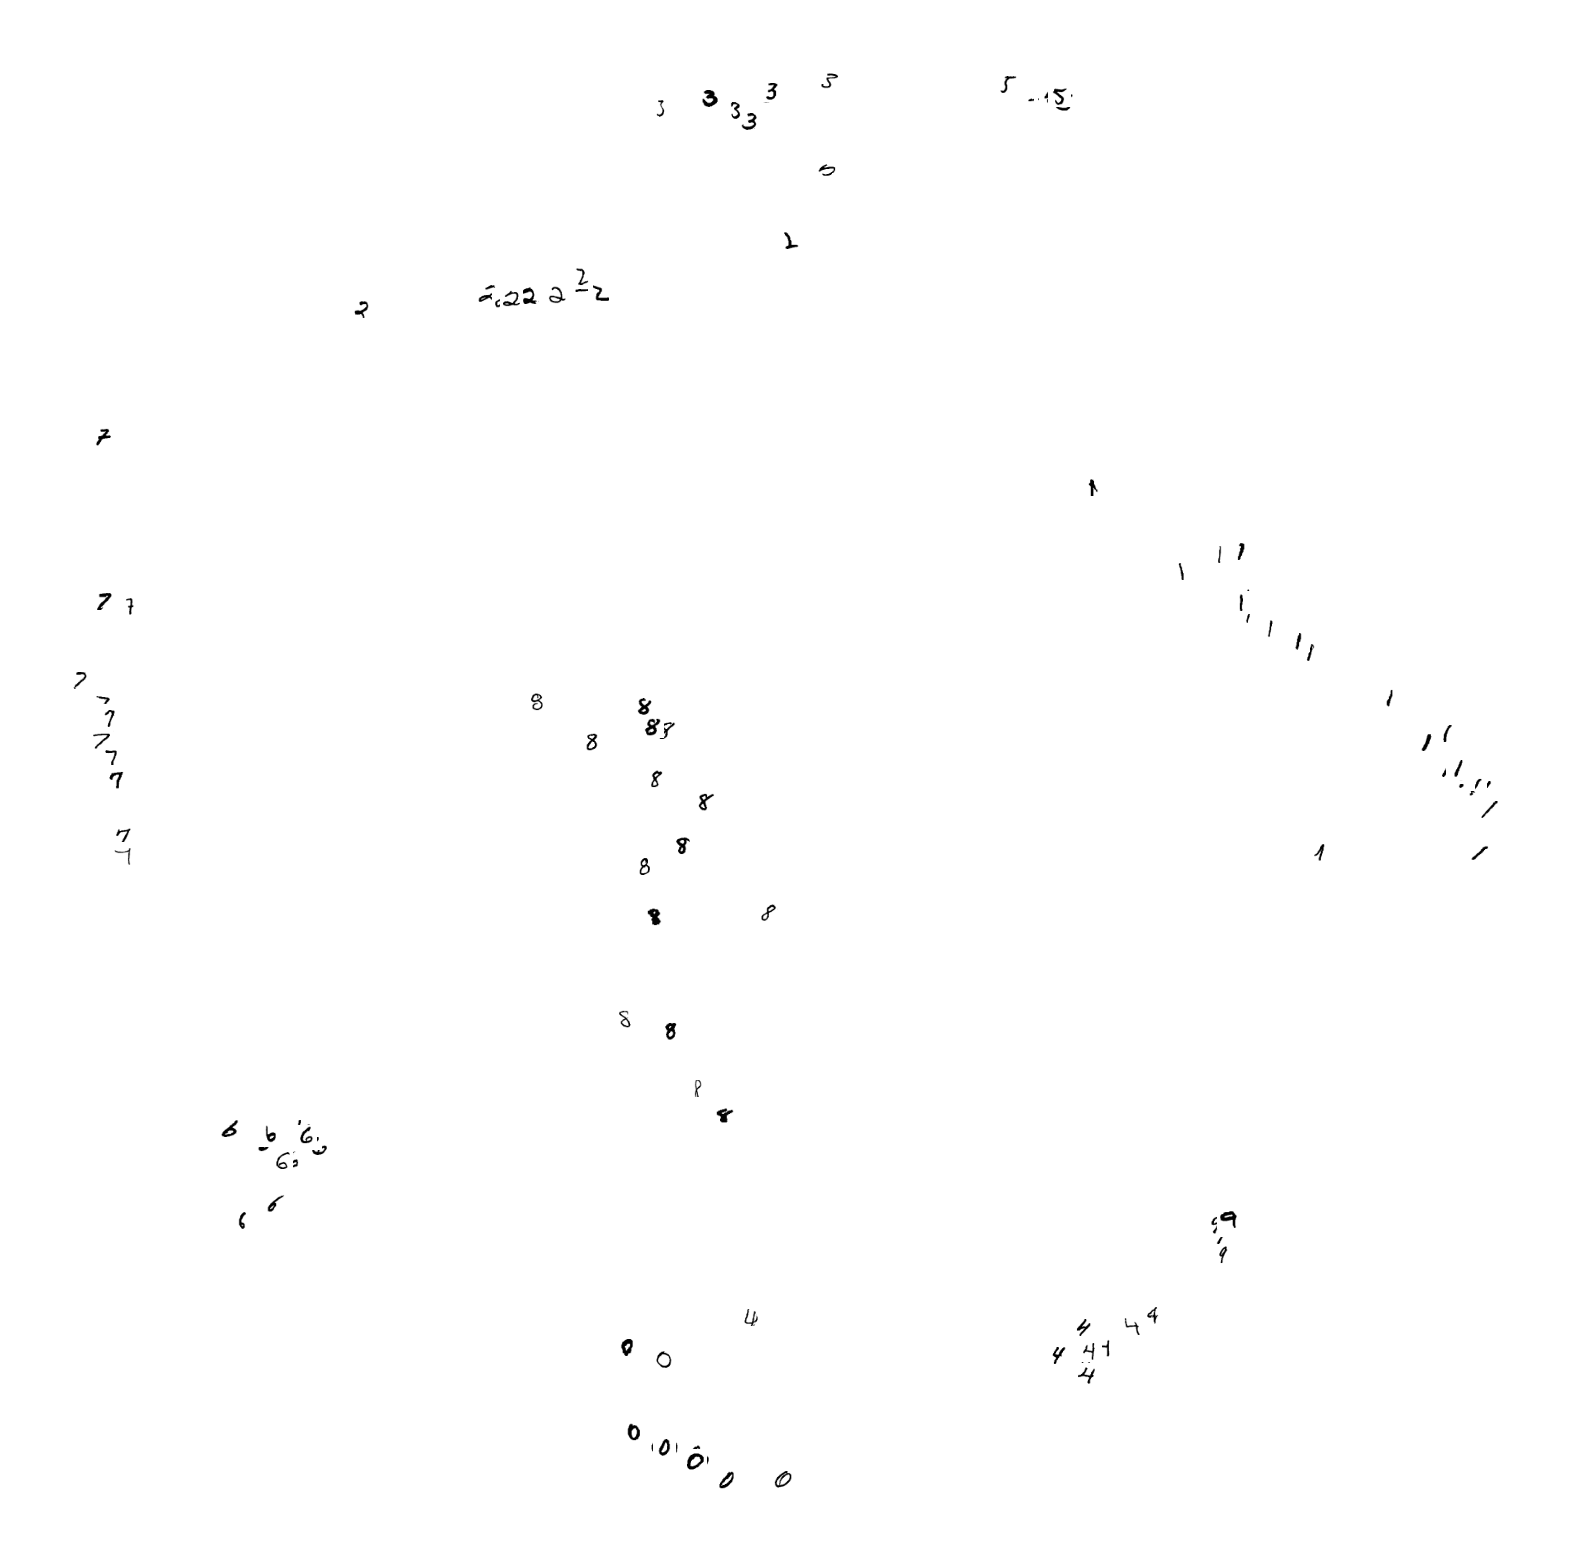

In [142]:
# CLAUDE

import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np

raw = datasets.MNIST("data", train=True, download=True)

Y = y.detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(20, 20))
ax.scatter(Y[:, 0], Y[:, 1], s=0)          # sets the axis limits

for (px, py), j in zip(Y, ixs):
    img = np.array(raw[j][0])              # PIL to array
    ab = AnnotationBbox(OffsetImage(img, cmap="gray_r", zoom=0.6),
                        (px, py), frameon=False)
    ax.add_artist(ab)

ax.axis("off")
plt.show()